# 8 · Estimating capital mobility `μ` across the EU

In the coupled model, capital moves toward departments with an above-average rate of profit. `_mobility_flow` adds `μ · (rᵢ − r̄) · Kᵢ` to each department's accumulation, with `r̄` the `K`-weighted mean, so the term sums to zero: it reallocates capital, it does not create it. `μ` is set by assumption (0.3 by default). This notebook estimates it for the 27 EU member states, 1996–2024.

**What in the data is the mobility term?** Not capital growth: a country's capital also grows by reinvesting its own surplus (`σ_c Sᵢ` in the model), which rises with profitability too, so a regression of capital growth on the profit rate mixes `σ_c` and `μ`. Between countries, the transfer has its own national-accounts counterpart: **net foreign financing, minus the current account balance**. A country that invests more than it saves is financed by capital from abroad. So the estimating equation is

`−CAᵢₜ / Kᵢₜ = μ · (rᵢ,ₜ₋₁ − r̄ₜ₋₁) + error`,

with `K` at current replacement cost, `r` the model's own rate of profit (`valuation = :current_cost`, self-employed imputed) and `r̄` the EU27 aggregate. Both sides are in percent, so `μ` is in the model's units. The gap is lagged a year: capital responds to profitability it has seen.

The current account measures all foreign financing, of governments and banks as well as of productive capital, so it is a noisy measure of the model's flow. The noise is in the dependent variable, so it widens the standard errors rather than biasing `μ̂`, unless public or financial flows themselves track the profit-rate gap.

The data are the extract of notebook 7 (AMECO, 2026 release). The estimation uses [SpatialEconometrics.jl](https://github.com/randsley/SpatialEconometrics.jl), a notebook-only dependency installed by `julia install_deps.jl --notebooks` at a pinned commit, for the cross-sectional dependence tests, the spatial panel and the Driscoll–Kraay errors. The country centroids come from its data files: boundaries © OpenStreetMap contributors, under the ODbL.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using SpatialEconometrics   # notebook-only dependency: julia install_deps.jl --notebooks
using Plots, DataFrames, Statistics, LinearAlgebra, Random, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

In [2]:
"""One AMECOData per area, from the static extract."""
function load_area(raw, area)
    d = sort(raw[raw.country .== area, :], :year)
    s = Dict(String(n) => [ismissing(x) ? NaN : Float64(x) for x in d[!, n]] for n in names(raw)[4:end])
    return build_ameco_data(_resolve_country_code(area), collect(Int, d.year), s,
                            "AMECO extract (data/ameco_eu27.csv)")
end

"""Value of a series in a given year."""
inyear(years, x, y) = x[findfirst(==(y), years)]

"""Capital stock at current replacement cost (the price basis of `:current_cost`)."""
current_cost_K(d, y) = inyear(d.years, d.total_capital_stock, y) * inyear(d.years, d.GFCF_deflator, y) / 100

"""Remove unit means (country effects), or unit and period means (two-way effects)."""
within(M) = M .- mean(M; dims = 2)
twoway(M) = M .- mean(M; dims = 2) .- mean(M; dims = 1) .+ mean(M)

"""OLS slope of y on x (both already demeaned), with its classical standard error."""
function slope(y, x; dof = length(y) - 1)
    b = dot(x, y) / dot(x, x)
    u = y .- b .* x
    return b, sqrt(sum(abs2, u) / dof / dot(x, x))
end

"""OLS of y on [1 x], returning the slope and its classical standard error."""
function ols(y, x)
    X = hcat(ones(length(x)), x)
    b = X \ y
    u = y - X * b
    se = sqrt.(diag(inv(X'X)) .* (sum(abs2, u) / (length(y) - 2)))
    return b[2], se[2]
end

"""K-weighted dispersion of the profit rates along a simulated path."""
function dispersion_path(sol, p)
    N = length(p.e)
    map(sol.u) do X
        C, V = X[1:N], X[N+1:2N]
        r = _io_profit_rates(C, V, p.e .* V, p)
        r̄ = sum(r .* C) / sum(C)
        sqrt(sum(C .* (r .- r̄) .^ 2) / sum(C))
    end
end

dispersion_path (generic function with 1 method)

## 1. The panel

In [3]:
raw = CSV.read(joinpath("..", "..", "data", "ameco_eu27.csv"), DataFrame)
EU = "European Union (27)"
areas = String.(unique(raw.country))
countries = filter(!=(EU), areas)
eu = Dict(a => load_area(raw, a) for a in areas)

# The model's own profit rate: current prices, C at current replacement cost,
# the self-employed counted at the average employee's compensation.
ts = Dict(a => analyze_time_series_with_data(eu[a]; valuation = :current_cost,
                                             self_employed = :imputed) for a in areas)

const YEARS = 1996:2024
N, T = length(countries), length(YEARS)
inflow = [-100 * inyear(eu[a].years, eu[a].current_account, y) / current_cost_K(eu[a], y)
          for a in countries, y in YEARS]                                  # % of K
gap = [100 * (inyear(ts[a].years, ts[a].r, y - 1) - inyear(ts[EU].years, ts[EU].r, y - 1))
       for a in countries, y in YEARS]                                     # percentage points
(countries = N, years = (first(YEARS), last(YEARS)), missing = count(isnan, inflow) + count(isnan, gap))

(countries = 27, years = (1996, 2024), missing = 0)

27 countries, 29 years, no gaps.

## 2. Between countries: capital goes where profits are high

Average each country over the whole period first.

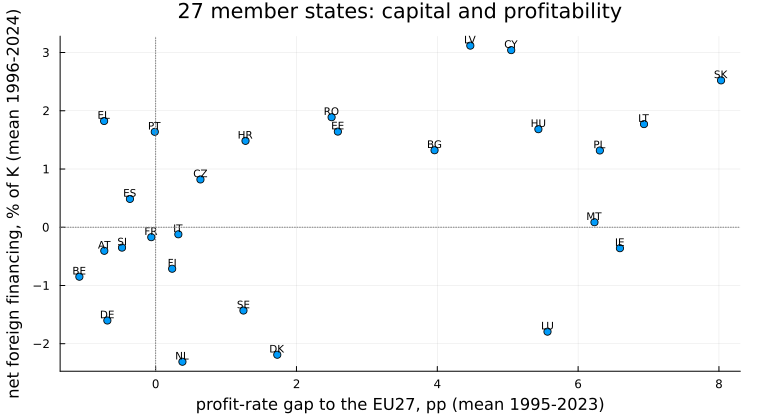

In [4]:
means = DataFrame(country = countries, code = _resolve_country_code.(countries),
                  inflow_pct_K = vec(mean(inflow; dims = 2)), r_gap_pp = vec(mean(gap; dims = 2)))
scatter(means.r_gap_pp, means.inflow_pct_K, series_annotations = text.(means.code, 7, :bottom),
        legend = false, xlabel = "profit-rate gap to the EU27, pp (mean 1995-2023)",
        ylabel = "net foreign financing, % of K (mean 1996-2024)",
        title = "27 member states: capital and profitability")
hline!([0], color = :gray, ls = :dot); vline!([0], color = :gray, ls = :dot)

Most of the member states that joined in 2004 or later sit in the upper right: profit rates above the EU27, by up to 8 points in Slovakia, and persistent foreign financing of 1–3% of their capital stock a year. Slovenia is the exception among them. Germany, Belgium, Austria and the Netherlands sit at or near the EU27 rate and export capital.

Two groups break the pattern. Luxembourg, Ireland and Malta combine high measured profit rates with capital *outflows*: they host financial centres and multinationals whose profits are booked there and owned from abroad. And Greece, Portugal and Spain received foreign financing of 0.5–1.8% of their capital a year at profit rates *below* the EU27: the credit boom of the euro's first decade, which profitability does not explain. Denmark and Sweden export capital at an above-average rate of profit.

In [5]:
FIN = ["Ireland", "Luxembourg", "Malta", "Cyprus"]
core = .!in(FIN).(countries)
b_all, se_all = ols(means.inflow_pct_K, means.r_gap_pp)
b_core, se_core = ols(means.inflow_pct_K[core], means.r_gap_pp[core])
@printf("between countries, all 27            μ̂ = %6.3f  (se %.3f)\n", b_all, se_all)
@printf("between countries, without %s  μ̂ = %6.3f  (se %.3f)\n",
        join(_resolve_country_code.(FIN), "/"), b_core, se_core)

between countries, all 27            μ̂ =  0.219  (se 0.098)


between countries, without IE/LU/MT/CY  μ̂ =  0.330  (se 0.099)


**Between countries, `μ̂` = 0.22** (standard error 0.10), and **0.33** (0.10) without Ireland, Luxembourg, Malta and Cyprus, whose accounts are dominated by financial and multinational flows. The second is almost exactly the model's default of 0.3.

This is a long-run association across 27 (or 23) averages, not yet a speed of adjustment: a country with a profit rate one point above the EU27 for thirty years received foreign financing of about a third of a percent of its capital stock a year more.

## 3. The common cycle

Notebook 13 of SpatialEconometrics found that a common factor dominates growth across European economies. Capital flows are the same.

net foreign financing: CD 9.24 (p = 0), alpha 0.73 [0.66, 0.81]


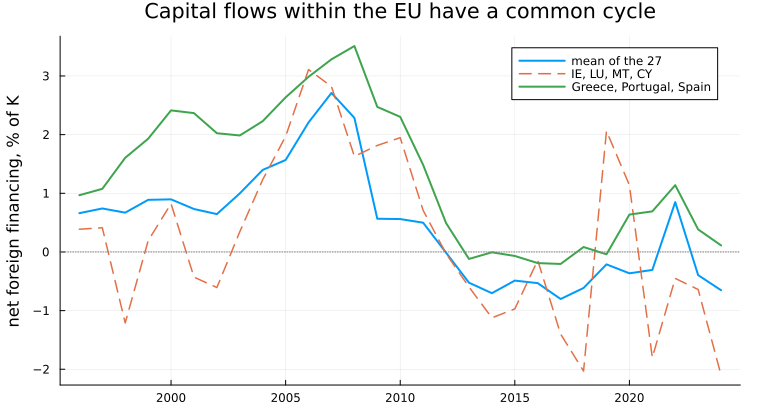

In [6]:
cd_y = pesaran_cd(vec(inflow), N, T)
ae_y = alpha_exponent(vec(inflow), N, T)
@printf("net foreign financing: CD %.2f (p = %.2g), alpha %.2f [%.2f, %.2f]\n",
        cd_y.stat, cd_y.p_value, ae_y.alpha, ae_y.ci[1], ae_y.ci[2])
plot(YEARS, vec(mean(inflow; dims = 1)), lw = 2, label = "mean of the 27",
     ylabel = "net foreign financing, % of K", title = "Capital flows within the EU have a common cycle")
plot!(YEARS, vec(mean(inflow[.!core, :]; dims = 1)), lw = 1.5, ls = :dash,
      label = join(_resolve_country_code.(FIN), ", "))
peri = in(["Greece", "Portugal", "Spain"]).(countries)
plot!(YEARS, vec(mean(inflow[peri, :]; dims = 1)), lw = 2, label = "Greece, Portugal, Spain")
hline!([0], color = :gray, ls = :dot, label = "")

Pesaran's CD is 9.2 and the exponent of cross-sectional dependence is **α̂ = 0.73** (0.66 to 0.81): strong dependence, so the flows have a common component that any year-by-year estimate has to remove. The chart shows it. Foreign financing of Greece, Portugal and Spain rose to 3.5% of their capital stock by 2008 and stopped within five years: the sudden stop of the euro crisis. Year effects remove the part of that cycle common to all 27.

## 4. Within countries: no response year to year

The model's `μ` is a speed: how much capital moves *this year* in response to *this year's* gap. That is a within-country question. Country effects remove each country's average, so the estimate comes from years in which a country's gap was above or below its own norm.

In [7]:
b_fe, se_fe = slope(vec(within(inflow)), vec(within(gap)); dof = N * T - N - 1)
b_tw, se_tw = slope(vec(twoway(inflow)), vec(twoway(gap)); dof = N * T - N - T)
cd_tw = pesaran_cd(vec(twoway(inflow) .- b_tw .* twoway(gap)), N, T)
@printf("within countries (country effects)   μ̂ = %6.3f  (se %.3f)\n", b_fe, se_fe)
@printf("within, country and year effects     μ̂ = %6.3f  (se %.3f)   residual CD %.2f (p = %.2f)\n",
        b_tw, se_tw, cd_tw.stat, cd_tw.p_value)

within countries (country effects)   μ̂ = -0.067  (se 0.039)
within, country and year effects     μ̂ = -0.009  (se 0.037)   residual CD -1.64 (p = 0.10)


**Within countries, `μ̂` is −0.07 (standard error 0.04) with country effects and −0.01 (0.04) with country and year effects.** The residual CD is −1.6 (p = 0.10): the year effects removed the common cycle. A year in which a country's profit rate rose above its usual gap brought no more foreign capital than any other.

### With neighbours, and with errors robust to common shocks

Inflows may cluster: the euro periphery and Central Europe each borrowed together. A spatial lag of the inflow over the four nearest countries (by centroid, from SpatialEconometrics' data) allows for that, and Driscoll–Kraay standard errors are robust to any remaining cross-sectional dependence.

In [8]:
cfile = joinpath(pkgdir(SpatialEconometrics), "notebooks", "data", "europe_countries.csv")
crow = [split(l, ','; limit = 9) for l in readlines(cfile)[2:end]]
centroid = Dict(r[1] => [parse(Float64, r[3]), parse(Float64, r[4])] ./ 1000 for r in crow)   # km, EPSG:3035
xy = permutedims(hcat([centroid[c] for c in means.code]...))
W4 = knn_weights(xy, 4)

m_sar = fit_spatial_panel(SAR(), TwoWayFE(), W4, reshape(vec(gap), :, 1), vec(inflow), N, T;
                          approach = DirectQML(), method = ExactLU(), varnames = ["r_gap"])
println(m_sar)
println(robust_coeftable(m_sar, DriscollKraayVCOV(max_lag = 3, kernel = BartlettKernel())))

═══════════════════════════════════════════════════════════════════════
Spatial Panel SAR Model — Direct QML — FE: Two-Way
───────────────────────────────────────────────────────────────────────
Parameter        |    Estimate |    Std. Err |     z-stat |    P>|z|
─────────────────┼─────────────┼─────────────┼────────────┼──────────────
r_gap            |     -0.0101 |      0.0348 |     -0.291 |  0.7712 
ρ                |      0.4470 |      0.0477 |      9.367 |  0.0000 ***
───────────────────────────────────────────────────────────────────────
ρ = 0.4470    σ² = 2.8380    Log-lik = -1501.75    N = 27    T = 29
═══════════════════════════════════════════════════════════════════════



Non-Parametric Spatio-Temporal Robust Inference: Driscoll-Kraay SCC
------------------------------------------------------------------------------------
Parameter      |     Estimate |     Robust SE |   Baseline SE |   Robust z
------------------------------------------------------------------------------------
r_gap          |      -0.0101 |        0.0830 |        0.0348 |      -0.12
ρ              |       0.4470 |        0.0005 |        0.0477 |     932.99


`μ̂` = −0.010, and the Driscoll–Kraay standard error is 0.083, more than twice the model-based 0.035. Nothing there. The spatial lag is large, **ρ̂ = 0.45**: a country's foreign financing moves with its neighbours' even after year effects, which is the regional clustering of the boom and the stop. (ρ̂'s own Driscoll–Kraay standard error, 0.0005, is not a measure of its precision; SpatialEconometrics' notebooks 11–13 show the same thing.)

In [9]:
m_cce = fit_sp_cce(vec(inflow), reshape(vec(gap), :, 1), W4, N, T; coefnames = ["r_gap"])
println(m_cce)

Spatial Common Correlated Effects (CCE)
═══════════════════════════════════════
  N = 27, T = 29,  augmented with: y, X
  Projected out per unit: 2 columns (54 total)

Parameter        |    Estimate |    Std. Err |     z-stat |    P>|z|
─────────────────┼─────────────┼─────────────┼────────────┼──────────────
rho              |      3.6159 |      2.7937 |      1.294 |  0.1956 
r_gap            |     -0.0036 |      0.0985 |     -0.037 |  0.9707 

  σ² = 6.743765
  First-stage F for Wy: 1.02   ← weak; ρ̂ is not reliable
  Sargan: 0.8674 (df = 1, p = 0.3517)



Spatial CCE, which removes common factors with a separate loading for each country, gives `μ̂` = −0.004 (0.098). Its spatial parameter is not identified here (first-stage F = 1.0), so read only `μ̂`, which agrees with the two-way estimate.

## 5. Before and after 2008

In [10]:
μ_period = Dict{String, Float64}()
for (label, cols) in (("1996-2008", findall(<=(2008), YEARS)), ("2009-2024", findall(>(2008), YEARS)))
    b, se = slope(vec(twoway(inflow[:, cols])), vec(twoway(gap[:, cols]));
                  dof = N * length(cols) - N - length(cols))
    @printf("%s  country and year effects  μ̂ = %6.3f  (se %.3f)\n", label, b, se)
    μ_period[label] = b
end

1996-2008  country and year effects  μ̂ =  0.149  (se 0.064)
2009-2024  country and year effects  μ̂ = -0.265  (se 0.053)


**Before the crisis, `μ̂` = 0.15 (0.06); after it, −0.27 (0.05).** From 1996 to 2008 capital did follow the profit-rate gap year by year, at half the model's default speed. After 2008 the relation ran the other way, while the financing of the periphery was withdrawn within five years. The full-period zero is the average of a mechanism that worked and a period in which something else drove the flows.

## 6. Back in the model

What do the estimates mean for the model's dynamics? Simulate the coupled three-department economy with each, from the same initial departments.

μ = 0: within, two-way           dispersion at t = 30: 0.0445
μ = 0.15: within, 1996-2008      dispersion at t = 30: 0.0402
μ = 0.33: between countries      dispersion at t = 30: 0.0361


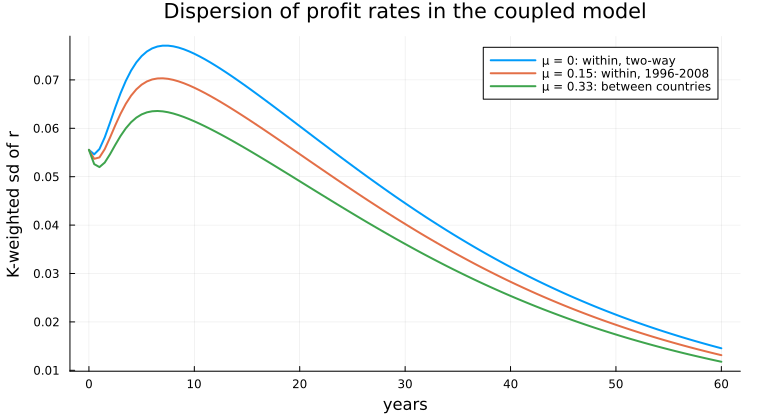

In [11]:
Random.seed!(11)
depts = create_departments(3, String[])
plt = plot(xlabel = "years", ylabel = "K-weighted sd of r", legend = :topright,
           title = "Dispersion of profit rates in the coupled model")
μ_pre = round(μ_period["1996-2008"], digits = 2)
μ_btw = round(b_core, digits = 2)
for (μ, lab) in ((0.0, "μ = 0: within, two-way"),
                 (μ_pre, "μ = $μ_pre: within, 1996-2008"),
                 (μ_btw, "μ = $μ_btw: between countries"))
    sol, _, p = simulate_Ndept_custom(deepcopy(depts); T = 60.0, seed = 1, coupled = true, μ = μ)
    d = dispersion_path(sol, p)
    plot!(plt, sol.t, d, lw = 2, label = lab)
    @printf("%-32s dispersion at t = 30: %.4f\n", lab, d[findfirst(>=(30.0), sol.t)])
end
plt

The profit rates converge in all three, because the departments' own accumulation also equalises them. Mobility speeds it up: at year 30 the dispersion is 0.045 with `μ` = 0, 0.040 with the pre-crisis 0.15 and 0.036 with the between-country 0.33.

## What the data say about `μ`

- **Across countries and over thirty years, capital went to where profits were high**, at `μ̂` ≈ 0.33 once the financial centres are set aside: the model's default value.
- **Year to year, the response is zero on average**, the sum of a positive response before 2008 (0.15) and a negative one after.
- **Capital flows have a strong common cycle** (α̂ = 0.73) **and cluster between neighbours** (ρ̂ = 0.45). Without year effects and robust errors, the cycle would be read as mobility.

So the mobility term describes a slow, structural force, the long catching-up of the 2004 entrants, that a financial crisis can override for a decade. A model in which `μ` is constant has no room for that; one in which `μ` depends on the state of credit would.